<a href="https://colab.research.google.com/github/solucionesmatematicas27-code/Actividad/blob/main/adam_colab_completo_py.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[A] Perdida de prueba   : 0.1478
[A] Exactitud de prueba : 0.9500


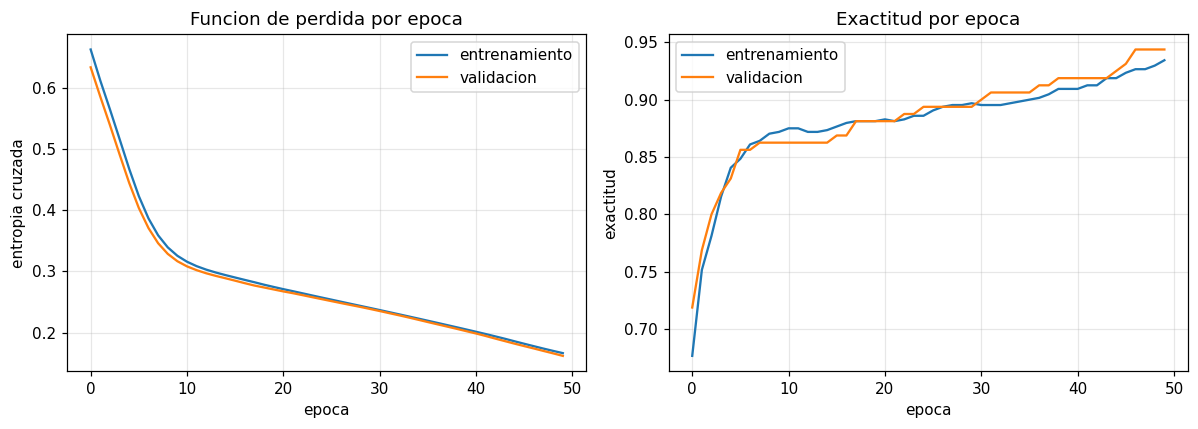

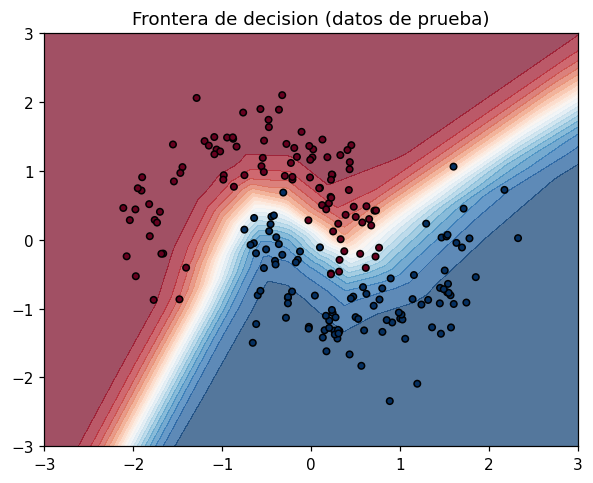

Ejemplo 1:  f(x,y) = x**2 + 10*y**2
gradiente = [2*x, 20*y]
theta_0 = (1, 1),  alpha_GD = 0.1,  alpha_Adam = 0.1,  n_iter = 30

  t |              GD (x, y)            f |            Adam (x, y)            f
  0 | (  1.00000,  1.00000)    11.000000 | (  1.00000,  1.00000)    11.000000
  1 | (  0.80000, -1.00000)    10.640000 | (  0.90000,  0.90000)     8.910002
  2 | (  0.64000,  1.00000)    10.409600 | (  0.80041,  0.80041)     7.047260
  3 | (  0.51200, -1.00000)    10.262144 | (  0.70159,  0.70159)     5.414461

Tras 30 iteraciones:  f_GD = 10   f_Adam = 0.0126924


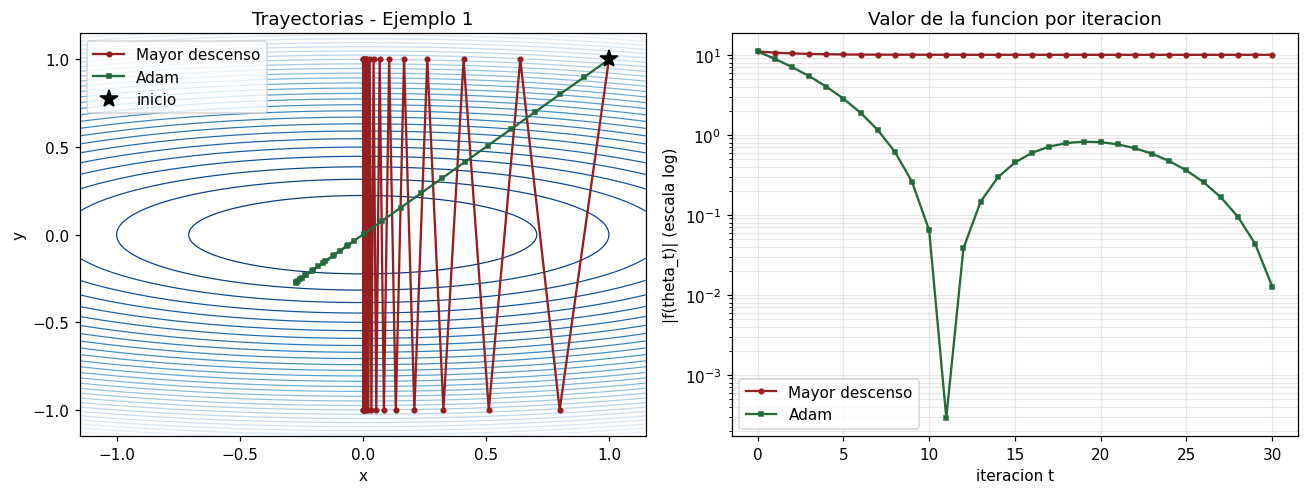

Ejemplo 2:  f(x,y) = 5*x**2 + 0.5*y**2
gradiente = [10*x, 1.0*y]
theta_0 = (1, 1),  alpha_GD = 0.1,  alpha_Adam = 0.1,  n_iter = 30

  t |              GD (x, y)            f |            Adam (x, y)            f
  0 | (  1.00000,  1.00000)     5.500000 | (  1.00000,  1.00000)     5.500000
  1 | (  0.00000,  0.90000)     0.405000 | (  0.90000,  0.90000)     4.455000
  2 | (  0.00000,  0.81000)     0.328050 | (  0.80041,  0.80041)     3.523629
  3 | (  0.00000,  0.72900)     0.265721 | (  0.70159,  0.70159)     2.707228

Tras 30 iteraciones:  f_GD = 0.000898505   f_Adam = 0.00634586


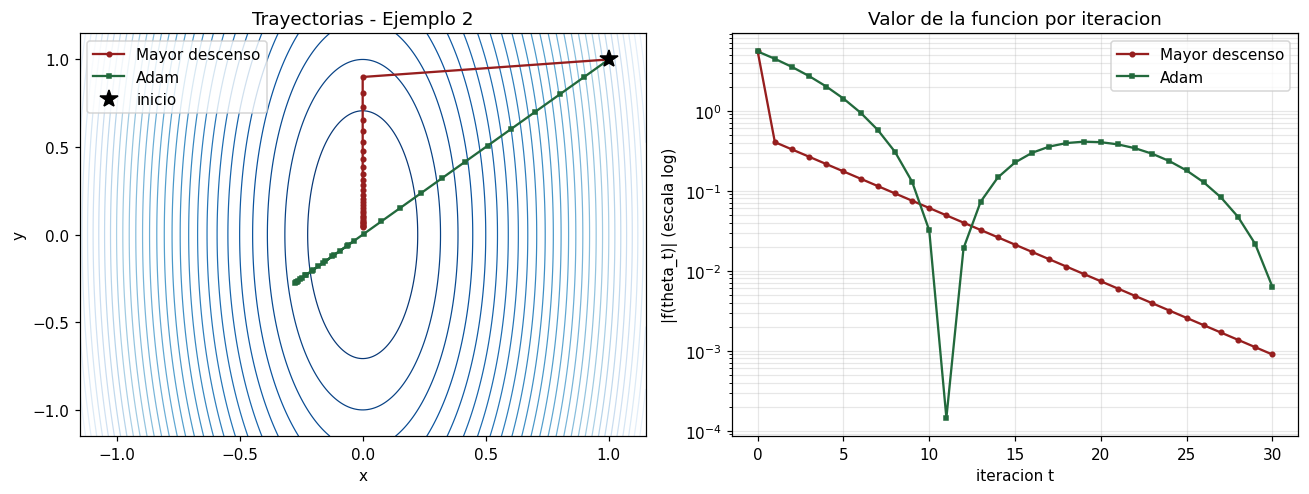

Rosenbrock:  f(x,y) = (1 - x)**2 + 100*(-x**2 + y)**2
gradiente = [-400*x*(-x**2 + y) + 2*x - 2, -200*x**2 + 200*y]
theta_0 = (-1.0, 1.0),  alpha_GD = 0.001,  alpha_Adam = 0.02,  n_iter = 2000

  t |              GD (x, y)            f |            Adam (x, y)            f
  0 | ( -1.00000,  1.00000)     4.000000 | ( -1.00000,  1.00000)     4.000000
  1 | ( -0.99600,  1.00000)     3.990390 | ( -0.98000,  1.00000)     4.077216
  2 | ( -0.99519,  0.99840)     3.987182 | ( -0.98969,  0.98512)     3.962031

Tras 2000 iteraciones:  f_GD = 0.0741759   f_Adam = 5.94149e-16


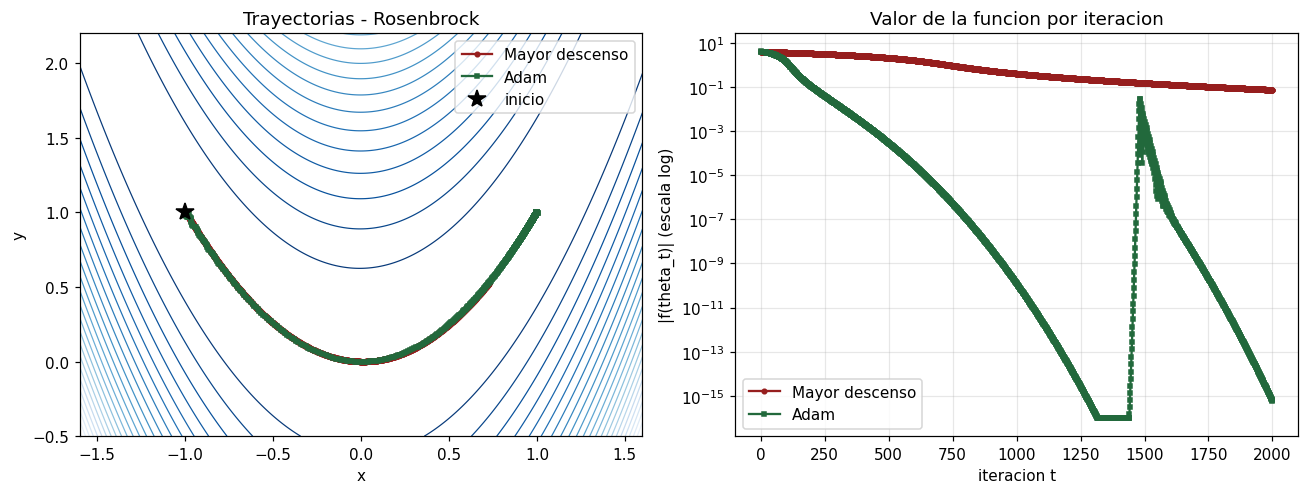

Cuadratica rotada:  f(x,y) = x**2 + 1.8*x*y + y**2
gradiente = [2*x + 1.8*y, 1.8*x + 2*y]
theta_0 = (2.0, -1.0),  alpha_GD = 0.2,  alpha_Adam = 0.1,  n_iter = 60

  t |              GD (x, y)            f |            Adam (x, y)            f
  0 | (  2.00000, -1.00000)     1.400000 | (  2.00000, -1.00000)     1.400000
  1 | (  1.56000, -1.32000)     0.469440 | (  1.90000, -1.10000)     1.058000
  2 | (  1.41120, -1.35360)     0.385358 | (  1.80093, -1.19841)     0.794689

Tras 60 iteraciones:  f_GD = 0.00335552   f_Adam = 0.00359127


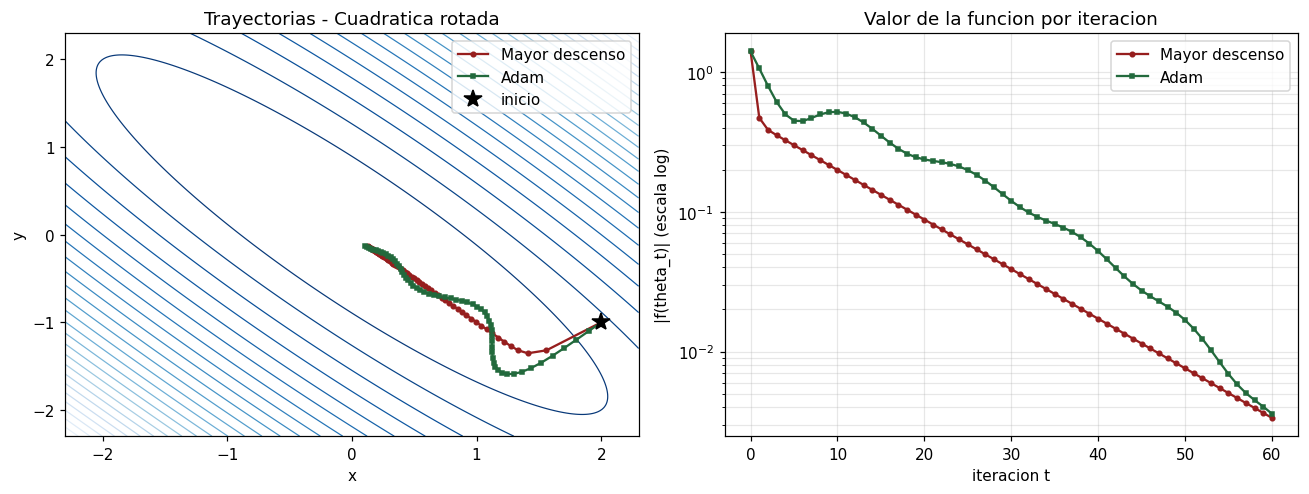

In [1]:
# =====================================================================
#  ENTRENAMIENTO DE UNA RED NEURONAL CON ADAM + COMPARACION GENERAL
#  "MAYOR DESCENSO vs ADAM" PARA CUALQUIER FUNCION f(x, y) EN R^2
#  Para ejecutar en Google Colab (cada bloque "CELDA" va en una celda).
#  Autor: Luis Andres -- UIS, Escuela de Matematicas
# =====================================================================


# ---------------------------------------------------------------------
# CELDA 1: importaciones y configuracion general
# ---------------------------------------------------------------------
import os                                   # utilidades del sistema operativo
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"    # silencia mensajes internos de TensorFlow
import numpy as np                          # calculo numerico y vectores
import matplotlib.pyplot as plt             # graficos
import sympy as sp                          # derivadas simbolicas (gradiente automatico)
from sklearn.datasets import make_moons     # genera un conjunto de datos no lineal
from sklearn.model_selection import train_test_split   # divide en entrenamiento/prueba
from sklearn.preprocessing import StandardScaler       # estandariza las variables
import tensorflow as tf                     # biblioteca de redes neuronales
from tensorflow.keras.models import Sequential         # modelo capa por capa
from tensorflow.keras.layers import Dense, Input       # capas densas y de entrada
from tensorflow.keras.optimizers import Adam           # optimizador Adam de Keras

SEMILLA = 42                                # semilla para resultados reproducibles
np.random.seed(SEMILLA)                     # fija la semilla de NumPy
tf.keras.utils.set_random_seed(SEMILLA)     # fija la semilla de TensorFlow y Python
plt.rcParams.update({"figure.dpi": 110})    # resolucion de los graficos en pantalla


# ---------------------------------------------------------------------
# CELDA 2: PARTE A -- entrenamiento de la red neuronal (9 pasos)
# ---------------------------------------------------------------------
def parte_a_red_neuronal(epocas=50, lr=0.001):
    """Entrena una red 2-16-8-1 con Adam sobre el conjunto 'make_moons'."""

    # PASO 3: crear el conjunto de datos sinteticos (clasificacion binaria)
    X, y = make_moons(n_samples=1000,       # 1000 puntos
                      noise=0.2,            # ruido gaussiano para datos realistas
                      random_state=SEMILLA) # reproducibilidad

    # PASO 4: dividir en 80 % entrenamiento y 20 % prueba
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, random_state=SEMILLA)

    # PASO 5: normalizar (media 0, varianza 1) para ayudar a la convergencia
    escala = StandardScaler()               # crea el escalador
    X_tr = escala.fit_transform(X_tr)       # ajusta con entrenamiento y transforma
    X_te = escala.transform(X_te)           # transforma prueba con los MISMOS parametros

    # PASO 6: construir la red neuronal
    modelo = Sequential([
        Input(shape=(2,)),                  # entrada: 2 caracteristicas (x1, x2)
        Dense(16, activation="relu"),       # oculta 1: 16 neuronas con ReLU
        Dense(8, activation="relu"),        # oculta 2: 8 neuronas con ReLU
        Dense(1, activation="sigmoid"),     # salida: probabilidad de la clase 1
    ])

    # PASO 7: compilar con el optimizador Adam
    adam = Adam(learning_rate=lr,           # alpha = tamano del paso
                beta_1=0.9,                 # beta1: memoria del primer momento
                beta_2=0.999,               # beta2: memoria del segundo momento
                epsilon=1e-7)               # epsilon: evita dividir por cero
    modelo.compile(optimizer=adam,
                   loss="binary_crossentropy",   # perdida para clasificacion binaria
                   metrics=["accuracy"])         # metrica: exactitud

    # PASO 8: entrenar el modelo
    hist = modelo.fit(X_tr, y_tr,
                      epochs=epocas,        # recorridos completos del conjunto
                      batch_size=32,        # actualiza pesos cada 32 muestras
                      validation_split=0.2, # 20 % del entrenamiento para validar
                      verbose=0)            # no imprime cada epoca

    # PASO 9: evaluar en datos de prueba nunca vistos
    perdida, exactitud = modelo.evaluate(X_te, y_te, verbose=0)
    print(f"[A] Perdida de prueba   : {perdida:.4f}")
    print(f"[A] Exactitud de prueba : {exactitud:.4f}")

    # ---- Grafico 1: perdida y exactitud por epoca ----
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(hist.history["loss"], label="entrenamiento")        # perdida train
    ax[0].plot(hist.history["val_loss"], label="validacion")       # perdida val
    ax[0].set_xlabel("epoca"); ax[0].set_ylabel("entropia cruzada")
    ax[0].set_title("Funcion de perdida por epoca"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(hist.history["accuracy"], label="entrenamiento")    # exactitud train
    ax[1].plot(hist.history["val_accuracy"], label="validacion")   # exactitud val
    ax[1].set_xlabel("epoca"); ax[1].set_ylabel("exactitud")
    ax[1].set_title("Exactitud por epoca"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig("fig_A_perdida_exactitud.png"); plt.show()

    # ---- Grafico 2: frontera de decision aprendida ----
    g1, g2 = np.meshgrid(np.linspace(-3, 3, 250), np.linspace(-3, 3, 250))  # malla 2D
    malla = np.c_[g1.ravel(), g2.ravel()]                          # puntos de la malla
    prob = modelo.predict(malla, verbose=0).reshape(g1.shape)      # probabilidad en cada punto
    plt.figure(figsize=(5.5, 4.5))
    plt.contourf(g1, g2, prob, levels=20, cmap="RdBu", alpha=.7)   # mapa de probabilidades
    plt.scatter(X_te[:, 0], X_te[:, 1], c=y_te, cmap="RdBu",
                edgecolor="k", s=18)                               # datos de prueba
    plt.title("Frontera de decision (datos de prueba)")
    plt.tight_layout(); plt.savefig("fig_A_frontera.png"); plt.show()
    return modelo, hist


# ---------------------------------------------------------------------
# CELDA 3: PARTE B -- metodos de optimizacion en R^2 (desde cero)
# ---------------------------------------------------------------------
def construir_funcion(expr_str):
    """Recibe un texto como 'x**2 + 10*y**2' y devuelve f y su gradiente."""
    x, y = sp.symbols("x y")                          # variables simbolicas
    expr = sp.sympify(expr_str)                       # texto -> expresion simbolica
    grad_sim = [sp.diff(expr, x), sp.diff(expr, y)]   # derivadas parciales exactas
    f_num = sp.lambdify((x, y), expr, "numpy")        # f(x, y) numerica
    g_num = sp.lambdify((x, y), grad_sim, "numpy")    # (df/dx, df/dy) numerico
    f = lambda th: float(f_num(th[0], th[1]))                      # f(theta)
    grad = lambda th: np.array(g_num(th[0], th[1]), dtype=float)   # gradiente
    return f, grad, expr, grad_sim


def mayor_descenso(grad, th0, alpha, n_iter):
    """theta_{t+1} = theta_t - alpha * grad f(theta_t)."""
    th = np.array(th0, dtype=float)       # punto actual
    tray = [th.copy()]                    # lista de puntos visitados
    for _ in range(n_iter):               # repite n_iter veces
        th = th - alpha * grad(th)        # paso en sentido contrario al gradiente
        tray.append(th.copy())            # guarda el nuevo punto
    return np.array(tray)                 # matriz (n_iter+1) x 2


def adam(grad, th0, alpha, n_iter, beta1=0.9, beta2=0.999, eps=1e-8):
    """Adam completo. Devuelve trayectoria y los vectores m, v, m_hat, v_hat."""
    th = np.array(th0, dtype=float)       # punto actual
    m = np.zeros_like(th)                 # primer momento, m_0 = 0
    v = np.zeros_like(th)                 # segundo momento, v_0 = 0
    tray = [th.copy()]                    # trayectoria
    reg = []                              # registro (g, m, v, m_hat, v_hat) por iteracion
    for t in range(1, n_iter + 1):        # t = 1, 2, ..., n_iter
        g = grad(th)                      # (1) gradiente actual
        m = beta1 * m + (1 - beta1) * g           # (2) primer momento
        v = beta2 * v + (1 - beta2) * g**2        # (3) segundo momento
        m_hat = m / (1 - beta1**t)        # (4) correccion del sesgo de m
        v_hat = v / (1 - beta2**t)        # (5) correccion del sesgo de v
        th = th - alpha * m_hat / (np.sqrt(v_hat) + eps)   # (6) actualizacion
        tray.append(th.copy())            # guarda el punto
        reg.append((g, m.copy(), v.copy(), m_hat, v_hat))  # guarda el registro
    return np.array(tray), reg


def valores_f(f, tray):
    """Evalua f en cada punto de una trayectoria."""
    with np.errstate(all="ignore"):       # ignora avisos de overflow si diverge
        return np.array([f(p) for p in tray])


def comparar(expr_str, th0=(1.0, 1.0), alpha_gd=0.1, alpha_adam=0.1,
             n_iter=30, eps=1e-8, nombre="funcion", ventana=None, n_tabla=3):
    """Resuelve con Mayor descenso y Adam, imprime tabla y dibuja los graficos."""
    f, grad, expr, grad_sim = construir_funcion(expr_str)   # f y gradiente
    print("=" * 66)
    print(f"{nombre}:  f(x,y) = {expr}")
    print(f"gradiente = {grad_sim}")
    print(f"theta_0 = {th0},  alpha_GD = {alpha_gd},  alpha_Adam = {alpha_adam},"
          f"  n_iter = {n_iter}")

    t_gd = mayor_descenso(grad, th0, alpha_gd, n_iter)       # trayectoria GD
    t_ad, reg = adam(grad, th0, alpha_adam, n_iter, eps=eps) # trayectoria Adam
    f_gd, f_ad = valores_f(f, t_gd), valores_f(f, t_ad)      # valores de f

    # ---- tabla de las primeras iteraciones ----
    print(f"\n{'t':>3} | {'GD (x, y)':>22} {'f':>12} | {'Adam (x, y)':>22} {'f':>12}")
    for t in range(n_tabla + 1):
        print(f"{t:>3} | ({t_gd[t,0]:9.5f},{t_gd[t,1]:9.5f}) {f_gd[t]:12.6f} | "
              f"({t_ad[t,0]:9.5f},{t_ad[t,1]:9.5f}) {f_ad[t]:12.6f}")
    print(f"\nTras {n_iter} iteraciones:  f_GD = {f_gd[-1]:.6g}   f_Adam = {f_ad[-1]:.6g}")

    # ---- graficos ----
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
    # ventana de dibujo: por defecto, cubre ambas trayectorias
    todos = np.vstack([t_gd, t_ad])
    todos = todos[np.all(np.isfinite(todos), axis=1)]
    if ventana is None:
        c = np.abs(todos).max() * 1.15 + 1e-9
        ventana = (-c, c, -c, c)
    X, Y = np.meshgrid(np.linspace(ventana[0], ventana[1], 300),
                       np.linspace(ventana[2], ventana[3], 300))   # malla para contornos
    with np.errstate(all="ignore"):
        Z = sp.lambdify(sp.symbols("x y"), expr, "numpy")(X, Y) * np.ones_like(X)
    ax[0].contour(X, Y, Z, levels=30, cmap="Blues_r", linewidths=.8)   # curvas de nivel
    ax[0].plot(t_gd[:, 0], t_gd[:, 1], "o-", color="#961E1E", ms=3,
               label="Mayor descenso")                                  # trayectoria GD
    ax[0].plot(t_ad[:, 0], t_ad[:, 1], "s-", color="#22693C", ms=3,
               label="Adam")                                            # trayectoria Adam
    ax[0].plot(*th0, "k*", ms=12, label="inicio")                       # punto inicial
    ax[0].set_xlim(ventana[0], ventana[1]); ax[0].set_ylim(ventana[2], ventana[3])
    ax[0].set_xlabel("x"); ax[0].set_ylabel("y")
    ax[0].set_title(f"Trayectorias - {nombre}"); ax[0].legend()

    piso = 1e-16                                                        # evita log(0) o negativos
    ax[1].semilogy(np.maximum(np.abs(f_gd), piso), "o-", color="#961E1E", ms=3,
                   label="Mayor descenso")                              # f vs iteracion (GD)
    ax[1].semilogy(np.maximum(np.abs(f_ad), piso), "s-", color="#22693C", ms=3,
                   label="Adam")                                        # f vs iteracion (Adam)
    ax[1].set_xlabel("iteracion t"); ax[1].set_ylabel("|f(theta_t)| (escala log)")
    ax[1].set_title("Valor de la funcion por iteracion")
    ax[1].grid(alpha=.3, which="both"); ax[1].legend()
    plt.tight_layout()
    plt.savefig(f"fig_B_{nombre.replace(' ', '_')}.png"); plt.show()
    return t_gd, t_ad


# ---------------------------------------------------------------------
# CELDA 4: ejemplos propuestos del informe
# ---------------------------------------------------------------------
def ejemplos_informe():
    # Ejemplo 1: f = x^2 + 10 y^2   (el mayor descenso oscila en y)
    comparar("x**2 + 10*y**2", th0=(1, 1), alpha_gd=0.1, alpha_adam=0.1,
             n_iter=30, eps=1e-5, nombre="Ejemplo 1")
    # Ejemplo 2: J = 5 x^2 + 0.5 y^2   (el mayor descenso anula x en un paso)
    comparar("5*x**2 + 0.5*y**2", th0=(1, 1), alpha_gd=0.1, alpha_adam=0.1,
             n_iter=30, eps=1e-7, nombre="Ejemplo 2")


# ---------------------------------------------------------------------
# CELDA 5: ZONA LIBRE -- cambia la funcion y los parametros a tu gusto
# ---------------------------------------------------------------------
def funciones_extra():
    # Rosenbrock: valle curvo estrecho, minimo en (1, 1)
    comparar("(1 - x)**2 + 100*(y - x**2)**2", th0=(-1.0, 1.0),
             alpha_gd=0.001, alpha_adam=0.02, n_iter=2000,
             nombre="Rosenbrock", ventana=(-1.6, 1.6, -0.5, 2.2), n_tabla=2)
    # Funcion libre (ejemplo): cuadratica rotada (no alineada con los ejes)
    comparar("x**2 + y**2 + 1.8*x*y", th0=(2.0, -1.0),
             alpha_gd=0.2, alpha_adam=0.1, n_iter=60,
             nombre="Cuadratica rotada", n_tabla=2)


# ---------------------------------------------------------------------
# CELDA 6: ejecucion principal
# ---------------------------------------------------------------------
if __name__ == "__main__":
    parte_a_red_neuronal()     # PARTE A: red neuronal con Adam
    ejemplos_informe()         # PARTE B: Ejemplos 1 y 2 con ambos metodos
    funciones_extra()          # PARTE B: otras funciones de R^2